# Visualizations — Reel Insights (TMDB)

This notebook explores the cleaned TMDB movie database with univariate, bivariate and multivariate charts. Every chart has a short insight.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

engine = create_engine("sqlite:///data/TMDB_database.db")

movies = pd.read_sql("SELECT * FROM movies", engine)
genres = pd.read_sql("SELECT * FROM genres", engine)
movie_genres = pd.read_sql("SELECT * FROM movie_genres", engine)



## Univariate

### Distribution of movie budgets using histogram

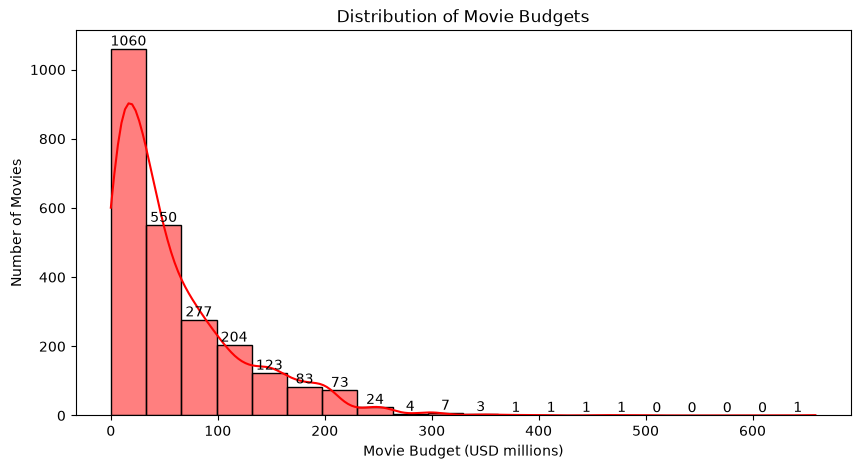

In [2]:
budget_data = movies[movies["budget"] > 0]

plt.figure(figsize=(10, 5))
ax=sns.histplot(budget_data["budget"] / 1e6,  bins=20,kde=True ,color="red")
ax.bar_label(ax.containers[0])
plt.title("Distribution of Movie Budgets")
plt.xlabel("Movie Budget (USD millions)")
plt.ylabel("Number of Movies")
plt.show()

**Insight:**

Most movies have relatively low production budgets.
Only a few movies have very high budgets.

### Distribution of runtimes using box plot

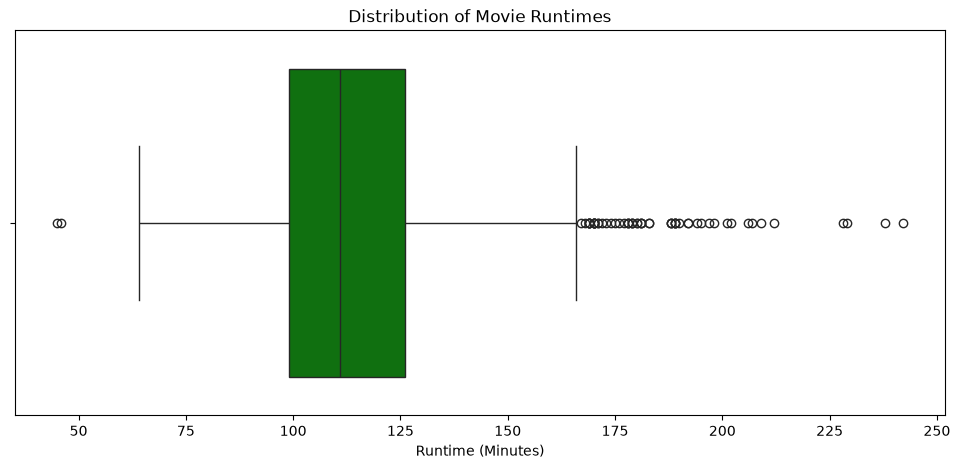

In [3]:
movies_rt = movies[movies["runtime"] > 0]

plt.figure(figsize=(12, 5))
sns.boxplot(x=movies_rt["runtime"], color="green")

plt.title("Distribution of Movie Runtimes")
plt.xlabel("Runtime (Minutes)")

plt.show()

**Insight:**

Most movies have runtimes within a common range.
Some movies have unusually short or long runtimes.

### Distribution of vote_average scores (histogram).

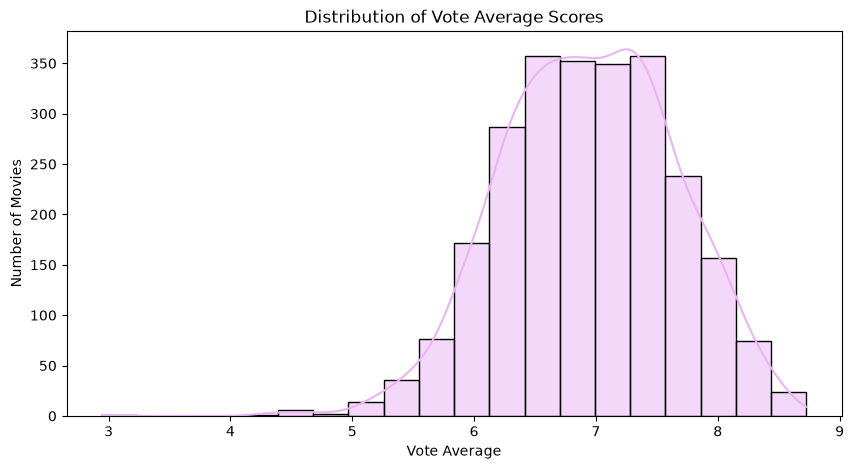

In [4]:
movies_va = movies[movies["vote_average"] > 0]

plt.figure(figsize=(10, 5))
sns.histplot(movies_va["vote_average"], bins=20, kde=True, color="#EAB3F5")

plt.title("Distribution of Vote Average Scores")
plt.xlabel("Vote Average")
plt.ylabel("Number of Movies")
plt.show()

**Insight:**

Most movies have ratings within the middle to higher range.
Very few movies have extremely low ratings.

### Count of movies per genre using count plot

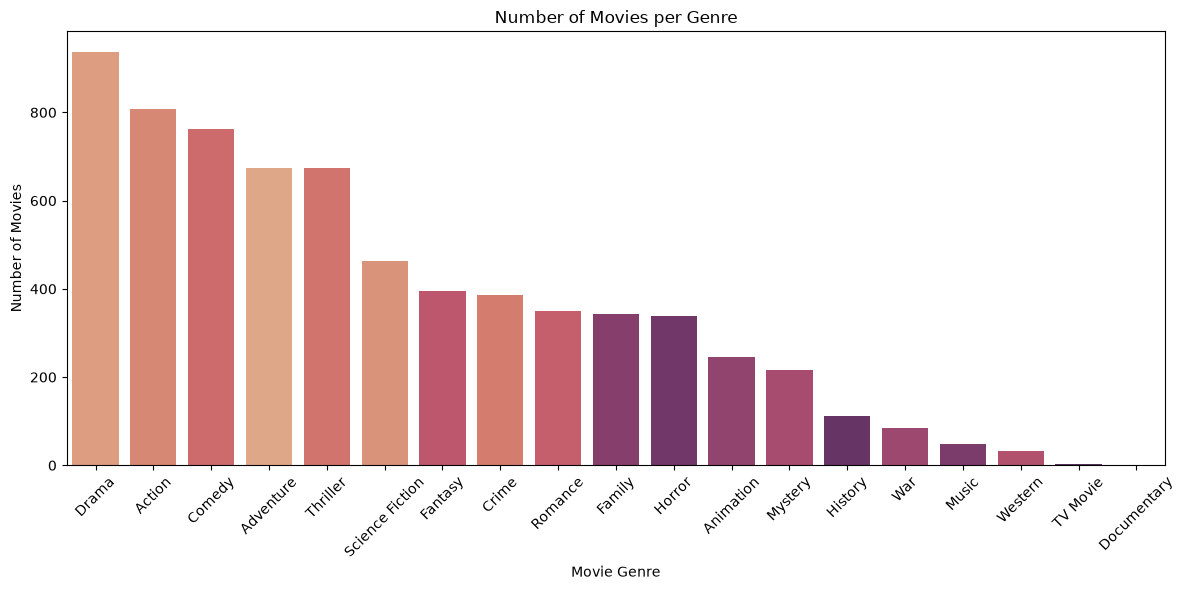

In [5]:
genre_data = movie_genres.merge(genres, on="genre_id", how="left")

plt.figure(figsize=(12, 6))

sns.countplot(
    data=genre_data,
    x="genre_name",
    order=genre_data["genre_name"].value_counts().index,
    hue="genre_name",
    palette="flare",
    legend=False
)
plt.title("Number of Movies per Genre")
plt.xlabel("Movie Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Insight:**

Some genres have more movies than others.
This shows that certain genres are more represented in the dataset.

## Bivariate

### Budget vs revenue (scatter plot, with trend line).

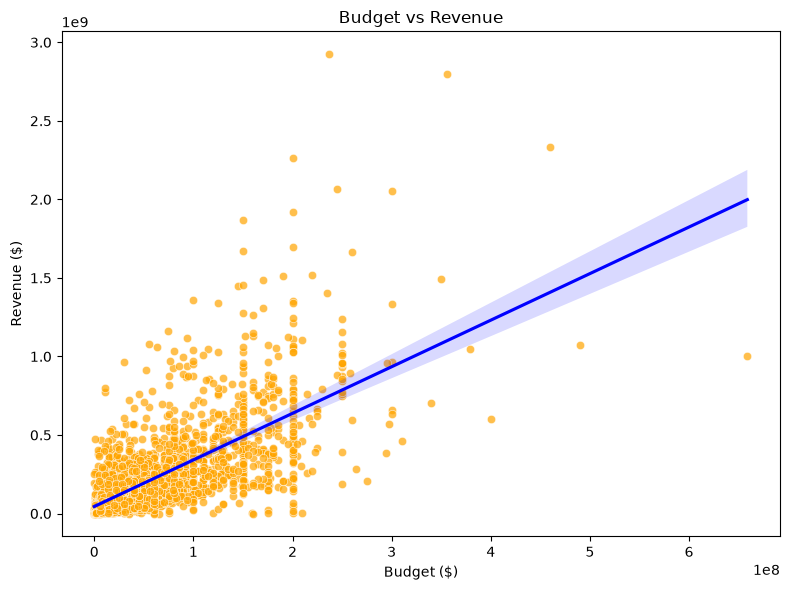

In [6]:
movies_br = movies[(movies["budget"] > 0) & (movies["revenue"] > 0)]

plt.figure(figsize=(8, 6))

# Scatter plot (points)
sns.scatterplot(
    data=movies_br,
    x="budget",
    y="revenue",
    alpha=0.7,
    color="orange"
)

# Trend line
sns.regplot(
    data=movies_br,
    x="budget",
    y="revenue",
    scatter=False,
    color="blue"
)

plt.title("Budget vs Revenue")
plt.xlabel("Budget ($)")
plt.ylabel("Revenue ($)")

plt.tight_layout()
plt.show()

**Insight:**

Movies with higher budgets often generate higher revenue.
However, some high-budget movies earn less revenue.

### Popularity vs vote count (scatter plot)

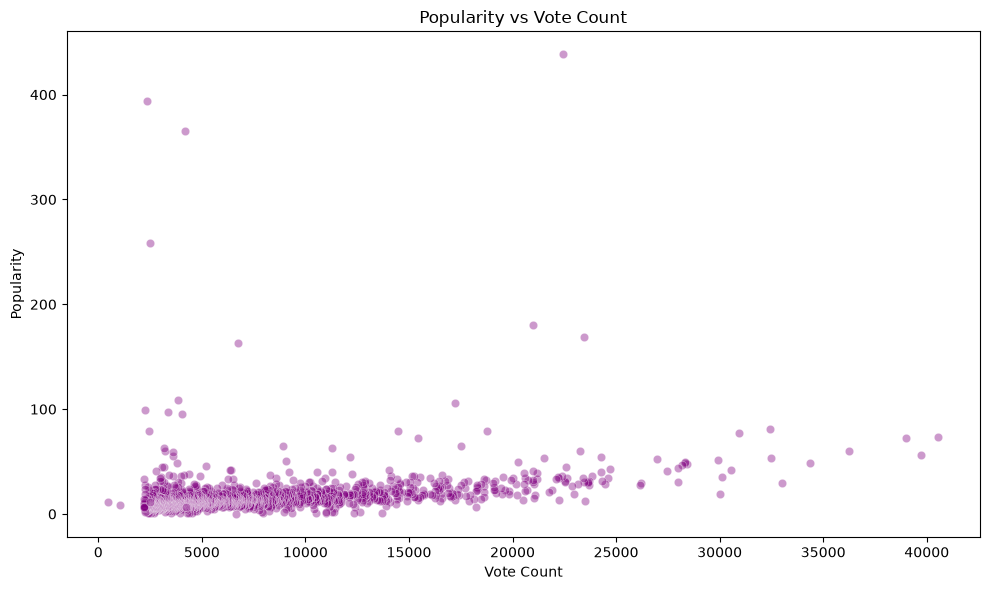

In [7]:
movies_pv = movies[(movies["popularity"] > 0) & (movies["vote_count"] > 0)]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=movies_pv,
    x="vote_count",
    y="popularity",
    alpha=0.4,
    color="purple"
)

plt.title("Popularity vs Vote Count")
plt.xlabel("Vote Count")
plt.ylabel("Popularity")

plt.tight_layout()
plt.show()

**Insight:**

Movies with more votes generally show higher popularity.
However, some movies have high popularity with fewer votes.

### Average rating by genre (bar chart).

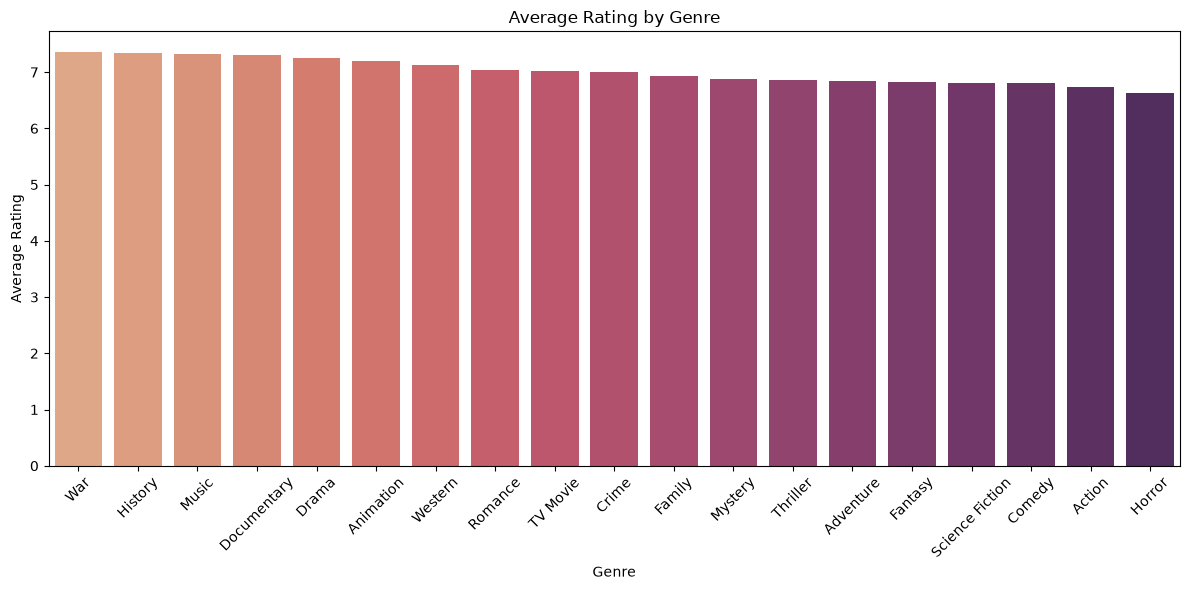

In [8]:
df = movies.merge(movie_genres, on="movie_id").merge(genres, on="genre_id")

avg_rating = df.groupby("genre_name")["vote_average"].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=avg_rating.index,
    y=avg_rating.values,
    hue=avg_rating.index,
    palette="flare",
    legend=False
)

plt.title("Average Rating by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Rating")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Insight:**

Average ratings are different across movie genres.
Some genres receive higher average ratings than others.

### Number of movies released per year bar chart .

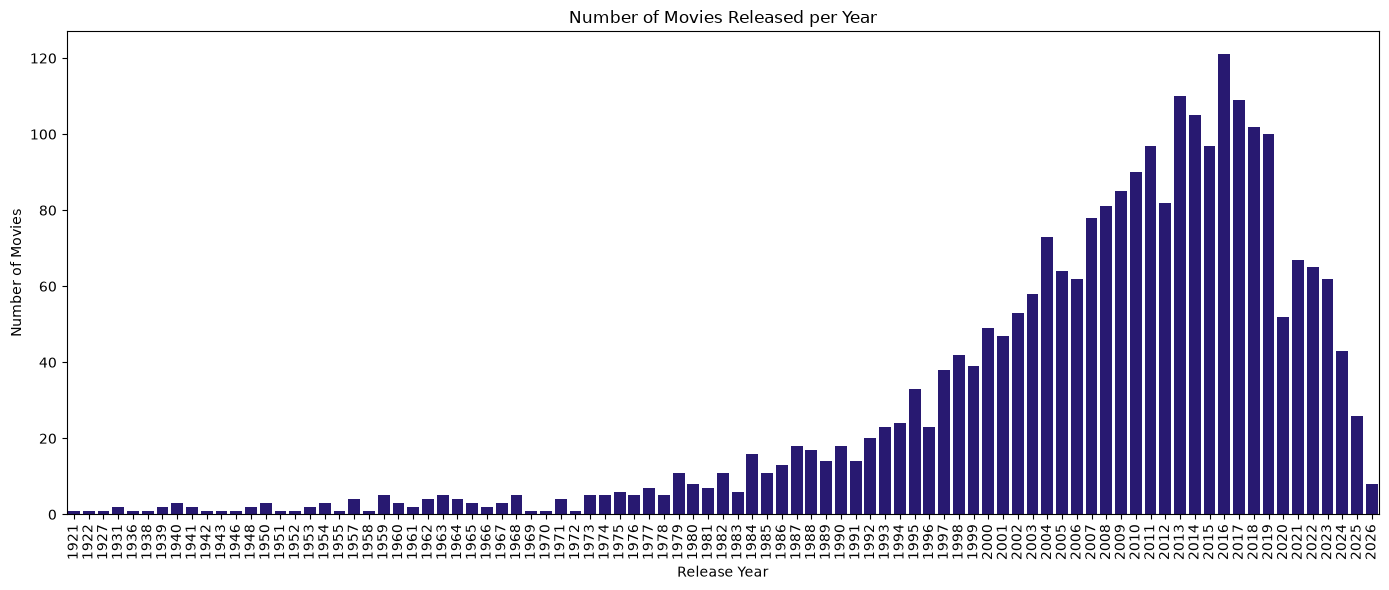

In [9]:
movies["release_year"] = pd.to_datetime(movies["release_date"]).dt.year

year_counts = movies["release_year"].value_counts().sort_index()

plt.figure(figsize=(14, 6))
sns.barplot(x=year_counts.index, y=year_counts.values, color="#1E0A80")

plt.title("Number of Movies Released per Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

**Insight:**

The number of movie releases changes across different years.
Some years have more movie releases than others.

## Multivariate

### Correlation heatmap of budget, revenue, runtime, popularity, vote_average and vote_count (heatmap).

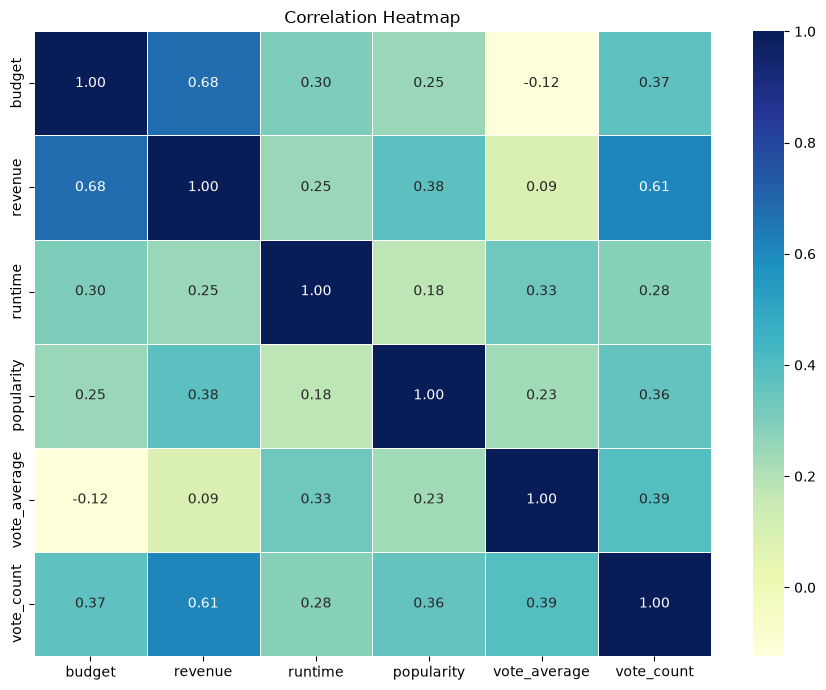

In [10]:
cols = ["budget", "revenue", "runtime", "popularity", "vote_average", "vote_count"]

df_corr = movies[(movies["budget"] > 0) & (movies["revenue"] > 0) & (movies["runtime"] > 0)]

corr = df_corr[cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="YlGnBu", linewidths=0.5)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

**Insight:**

Budget and revenue show a positive relationship.
The heatmap helps identify relationships between movie features.

### Pairplot of budget, revenue, popularity and vote_average, colored by primary genre (pairplot).

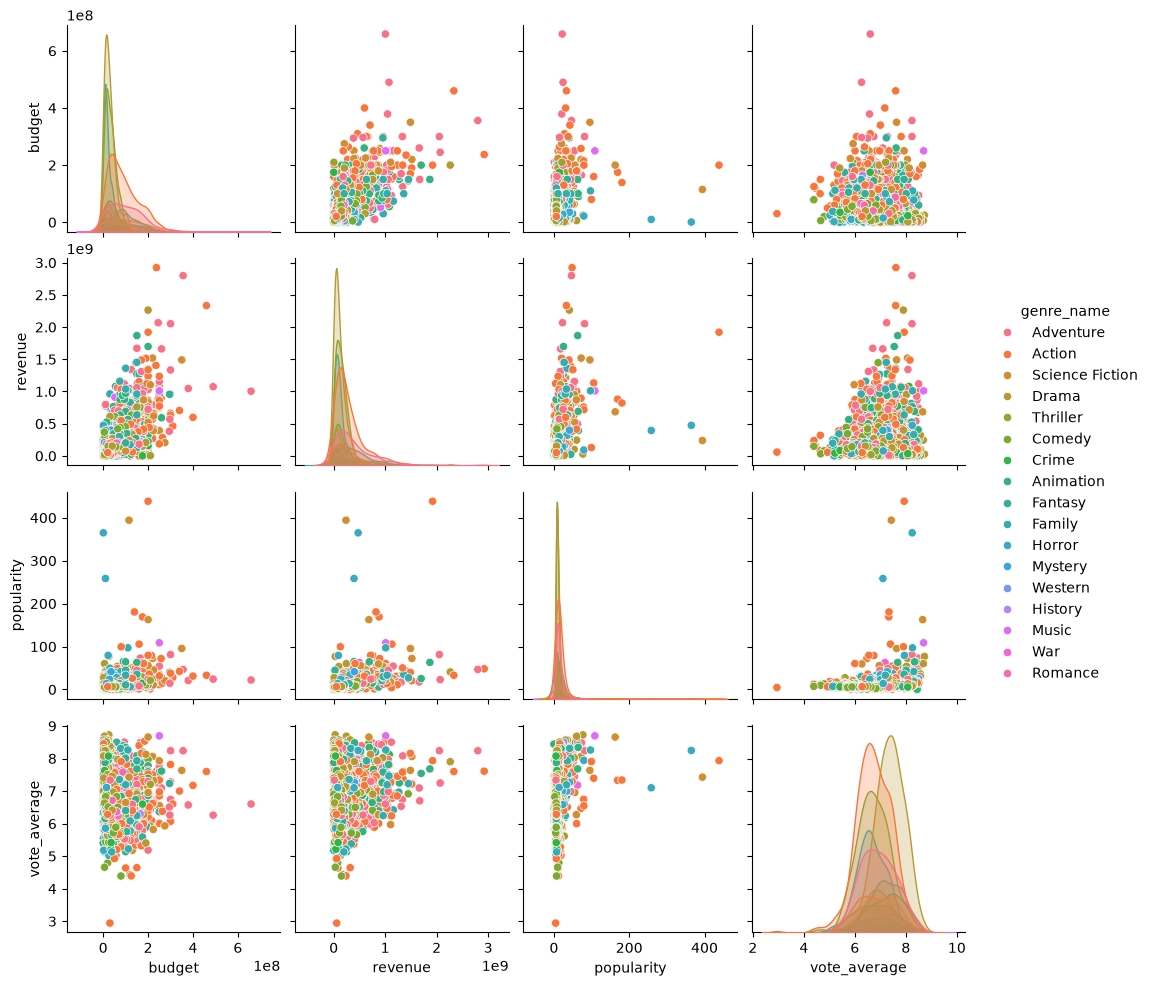

In [11]:
primary = movie_genres.merge(genres, on="genre_id").drop_duplicates("movie_id")

df = movies.merge(primary, on="movie_id")
df = df[
    (df["budget"] > 0) &
    (df["revenue"] > 0) &
    (df["popularity"] > 0) &
    (df["vote_average"] > 0)
]

sns.pairplot(df,vars=["budget", "revenue", "popularity", "vote_average"],hue="genre_name")
plt.show()

**Insight:**

The pairplot shows relationships between budget, revenue,
popularity and vote average.
It helps compare different movie features across genres.

### Budget vs revenue colored by primary genre, with point size showing vote_count (scatter plot with hue and size).

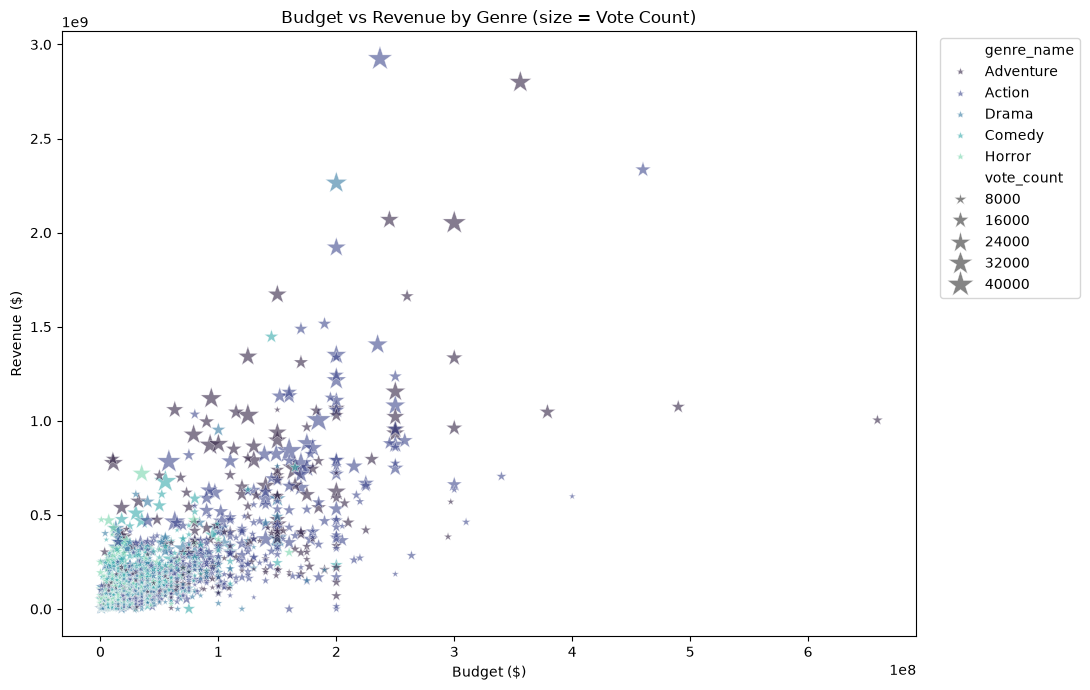

In [12]:
primary = movie_genres.merge(genres, on="genre_id").drop_duplicates("movie_id")

df = movies.merge(primary, on="movie_id")
df = df[(df["budget"] > 0) & (df["revenue"] > 0)]

# Top 5 genres mattum
top5 = df["genre_name"].value_counts().head(5).index
df = df[df["genre_name"].isin(top5)]

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=df,
    x="budget",
    y="revenue",
    hue="genre_name",
    size="vote_count",
    sizes=(20, 400),
    alpha=0.6,
    palette="mako",
    marker="*"
)

plt.title("Budget vs Revenue by Genre (size = Vote Count)")
plt.xlabel("Budget ($)")
plt.ylabel("Revenue ($)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

**Insight:**

Different genres show different budget and revenue patterns.
Larger points represent movies with higher vote counts.

### Distribution of vote_average for each genre in separate panels (FacetGrid with histograms).

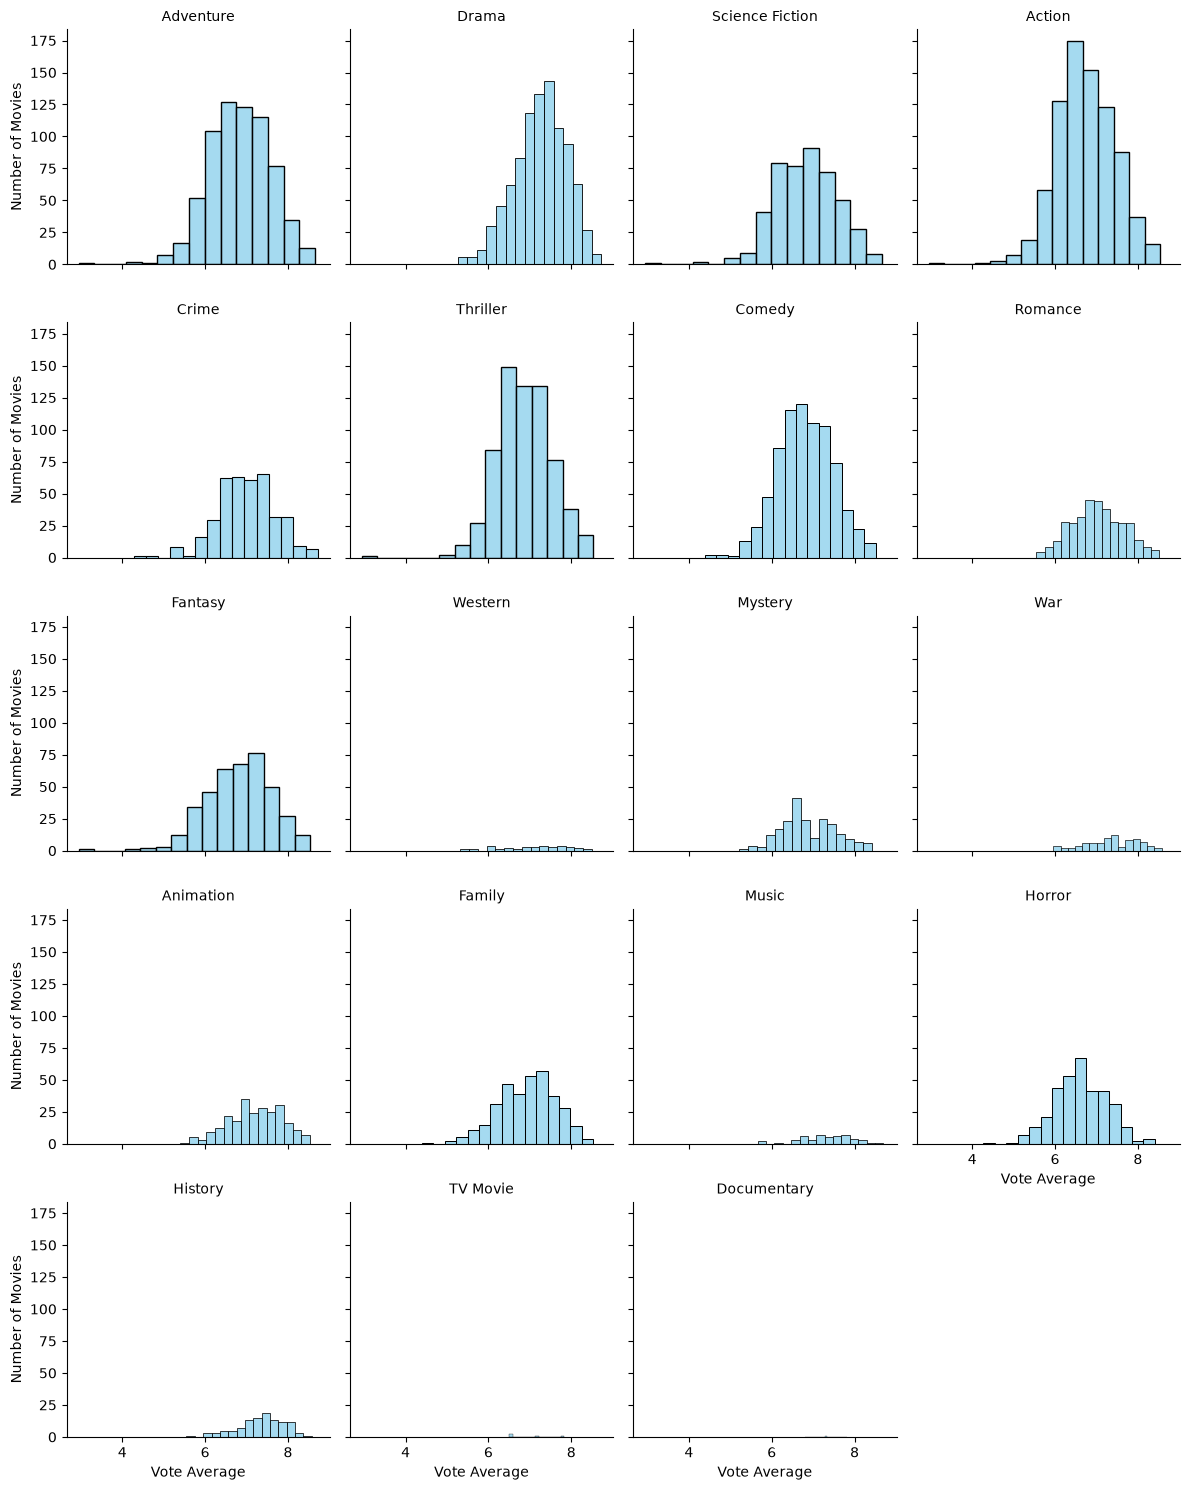

In [13]:
df = movies.merge(movie_genres, on="movie_id").merge(genres, on="genre_id")
df = df[df["vote_average"] > 0]

g = sns.FacetGrid(df, col="genre_name", col_wrap=4, height=3)
g.map(sns.histplot, "vote_average", bins=15, color="skyblue")

g.set_titles("{col_name}")
g.set_axis_labels("Vote Average", "Number of Movies")

plt.tight_layout()
plt.show()

**Insight:**
Different genres have different rating distributions.
Most genres contain movies with different rating levels.

### Average revenue by genre and release decade (heatmap of a pivot table).

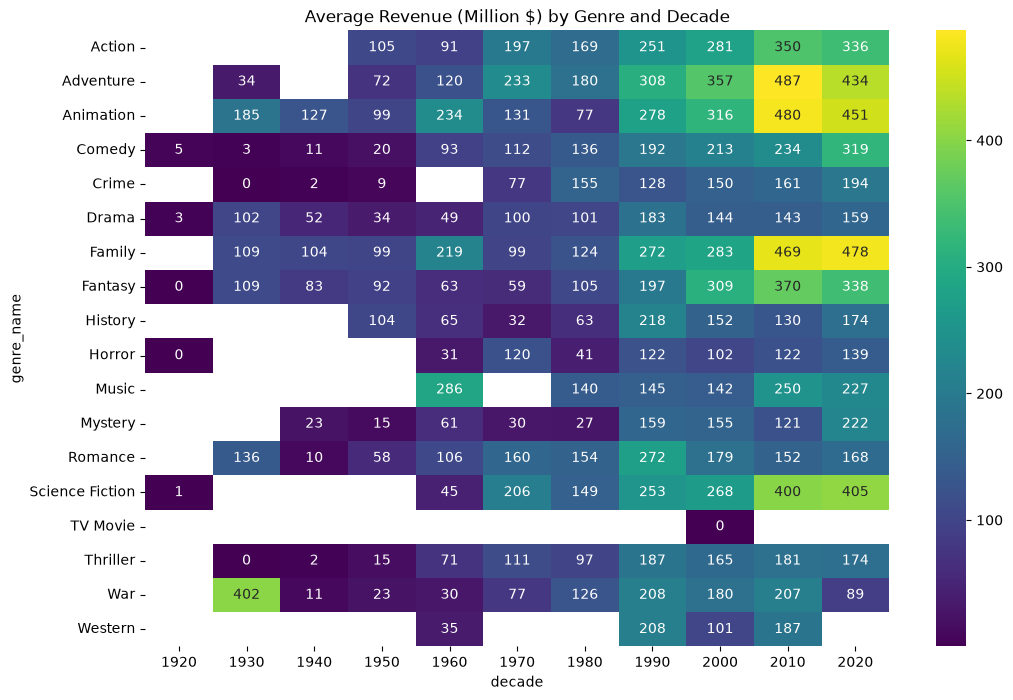

In [14]:
df = movies.merge(movie_genres, on="movie_id").merge(genres, on="genre_id")
df = df[df["revenue"] > 0]

df["decade"] = pd.to_datetime(df["release_date"]).dt.year // 10 * 10

pivot = df.pivot_table(index="genre_name", columns="decade", values="revenue", aggfunc="mean")

plt.figure(figsize=(12, 8))
sns.heatmap(pivot / 1e6, annot=True, fmt=".0f", cmap="viridis")

plt.title("Average Revenue (Million $) by Genre and Decade")
plt.show()

**Insight:**
Average revenue varies across genres and decades.
Some genres generate higher revenue in certain decades.